# Detecting Fraudulent Job Postings

**Research question.** Do text embeddings help detect fraudulent job postings more effectively than TF-IDF?

We compare TF-IDF and embeddings with two classifiers: logistic regression and random forest. This 2-by-2 design lets us compare representations within each classifier and classifiers within each representation.

We use the [Real or Fake? Fake Jobposting Prediction](https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction) dataset. Each row represents one job posting. The target, `fraudulent`, is `0` for legitimate postings and `1` for fraudulent postings. We use `job_id` to match records.

### Environment setup

Install the dependencies in the Python environment you select in Jupyter.

```bash
python -m pip install "pandas>=2.2,<4" "numpy>=2,<3" "matplotlib>=3.9,<4" "scikit-learn>=1.6,<2" lxml "joblib>=1.4,<2" "ipykernel>=6,<8" "nbconvert>=7,<8"
```

To generate the school embeddings cache, install `litellm` for embedding requests and `python-dotenv` to read the local settings.

```bash
python -m pip install litellm python-dotenv
```

We use `lxml` to clean HTML and `joblib` through scikit-learn to cache repeated TF-IDF transformations during tuning. `ipykernel` runs the notebook and `nbconvert` exports it to HTML.

## 1. Exploratory Data Analysis

We inspect the dataset size, column types, missing values, and class balance. We then compare the share of fraudulent postings across groups defined by company logo, remote-work flag, and employment type.

We also inspected other variables, but decided not to include every graph in our Jupyter Notebook, otherwise it would be too long.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path('data/fake_job_postings.csv')
jobs = pd.read_csv(DATA_PATH)

n_rows, n_columns = jobs.shape
print(f'Dataset size: {n_rows:,} rows × {n_columns} columns')
jobs[['job_id', 'title', 'location', 'employment_type', 'fraudulent']].head(5)

Dataset size: 17,880 rows × 18 columns


,job_id,title,location,employment_type,fraudulent
0,1,Marketing Intern,"US, NY, New York",Other,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Full-time,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Full-time,0
4,5,Bill Review Manager,"US, FL, Fort Worth",Full-time,0


### Data types and missing values

The table shows the data type, the number and share of missing values, and the missing rate within each class. We count empty and whitespace-only strings as missing. The chart shows fields with at least one missing value.

In [2]:
CLASS_LABELS = {0: "Legitimate", 1: "Fraudulent"}
CLASS_COLORS = {0: "#326C96", 1: "#BB5043"}
TEXT_COLOR = "#253747"


def style_axes(ax, title, grid_axis="y"):
    ax.set_title(title, loc="left", pad=12, fontweight="bold", color=TEXT_COLOR)
    ax.set_axisbelow(True)
    ax.grid(axis=grid_axis, color="#E1E8EF", linewidth=0.8)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0, pad=6, colors=TEXT_COLOR)
    ax.xaxis.label.set_color(TEXT_COLOR)
    ax.yaxis.label.set_color(TEXT_COLOR)

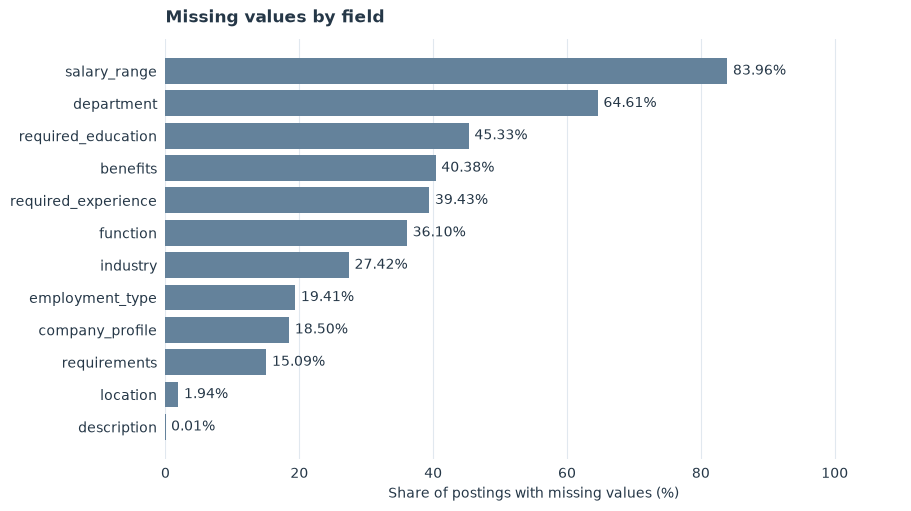

,Data type,Missing count,Missing (%),Missing in legitimate postings (%),Missing in fraudulent postings (%)
salary_range,str,15012,83.96,84.45,74.25
department,str,11553,64.61,64.78,61.32
required_education,str,8105,45.33,44.99,52.08
benefits,str,7220,40.38,40.30,42.03
required_experience,str,7050,39.43,38.88,50.23
function,str,6455,36.10,35.96,38.91
industry,str,4903,27.42,27.20,31.76
employment_type,str,3471,19.41,18.98,27.83
company_profile,str,3308,18.50,15.99,67.78
requirements,str,2698,15.09,14.95,17.78


In [3]:
missing = jobs.replace(r"^\s*$", pd.NA, regex=True).isna()
by_class = missing.groupby(jobs["fraudulent"], observed=True).mean().T
by_class = by_class.reindex(columns=[0, 1]) * 100

data_profile = pd.DataFrame({
    "Data type": jobs.dtypes.astype(str),
    "Missing count": missing.sum(),
    "Missing (%)": missing.mean() * 100,
    "Missing in legitimate postings (%)": by_class[0],
    "Missing in fraudulent postings (%)": by_class[1],
}).round(2).sort_values("Missing count", ascending=False)

with_missing = data_profile.loc[data_profile["Missing count"] > 0]

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
bars = ax.barh(with_missing.index, with_missing["Missing (%)"], color="#64829B")
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f%%", padding=4, color=TEXT_COLOR)
ax.set(xlabel="Share of postings with missing values (%)", xlim=(0, 110), xticks=range(0, 101, 20))
style_axes(ax, "Missing values by field", grid_axis="x")
plt.show()

data_profile

The fields most often missing are `salary_range` (84.0%) and `department` (64.6%). Around 40% of postings also lack `benefits`. This is the case for both legitimate and fraudulent postings. 

Interestingly, almost 70% of fraudulent job postings do not contain the variable `company_profile`, which is 4 times higher than in legitimate postings.

We replace missing values in the five text fields with empty strings so that we can keep any posting with text in at least one of those fields.

### Class balance

            Count  Percent
Class                     
Legitimate  17014    95.16
Fraudulent    866     4.84


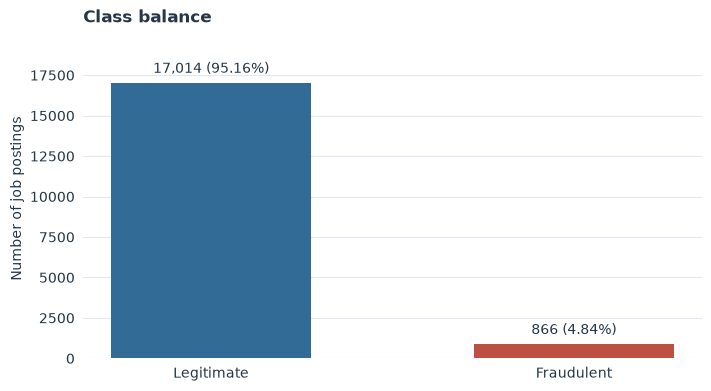

Always predicting legitimate gives 95.16% accuracy.


In [4]:
def analyze_class_balance(df):
    counts = df["fraudulent"].value_counts().reindex([0, 1], fill_value=0)
    percentages = counts / len(df) * 100
    summary = pd.DataFrame({"Count": counts, "Percent": percentages.round(2)})
    print(summary.rename(index=CLASS_LABELS).rename_axis("Class"))

    fig, ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
    bars = ax.bar(
        [CLASS_LABELS[label] for label in counts.index],
        counts,
        color=[CLASS_COLORS[label] for label in counts.index],
        width=0.55,
    )
    labels = [f"{count:,} ({pct:.2f}%)" for count, pct in zip(counts, percentages)]
    ax.bar_label(bars, labels=labels, padding=5, color=TEXT_COLOR)
    ax.set(ylabel="Number of job postings", ylim=(0, counts.max() * 1.16))
    style_axes(ax, "Class balance")
    plt.show()

    print(f"Always predicting legitimate gives {percentages[0]:.2f}% accuracy.")
    return summary

class_balance = analyze_class_balance(jobs)

Only **4.84%** of postings are fraudulent. Predicting every posting as legitimate would give **95.16% accuracy** on the original dataset and miss all **866 fraudulent postings**. We use F1 for model selection because it balances precision and recall for the fraudulent class. Average Precision (AP) summarizes precision and recall across score thresholds. The final test evaluation will also include accuracy.

### Job posting characteristics

Each bar shows the class breakdown within a group. The label above the bar gives the share of fraudulent postings. The label below gives the group size.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


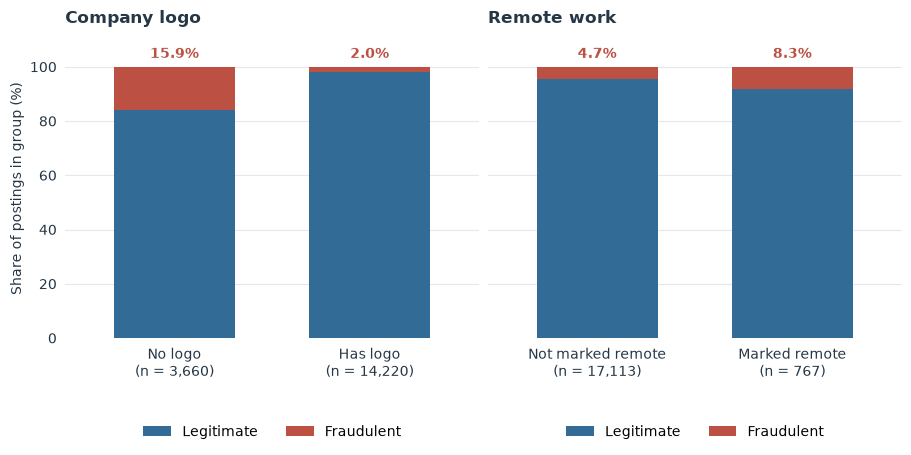

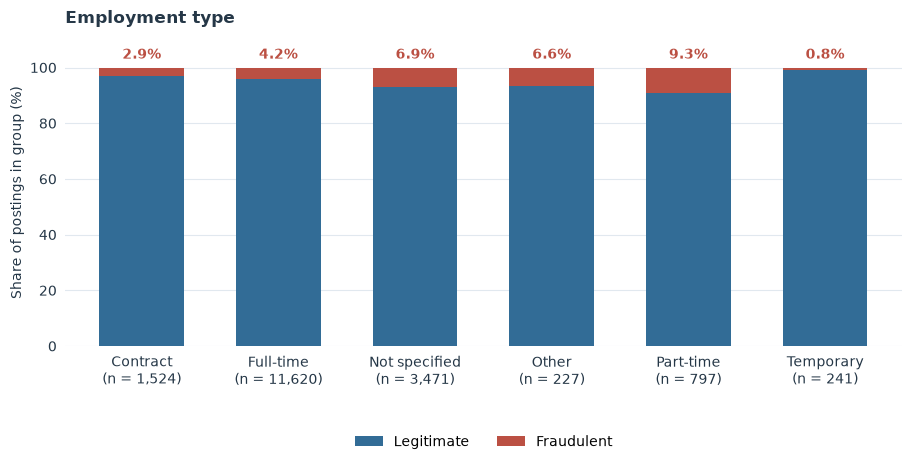

In [5]:
def fraud_bars(jobs, feature, ax, title, *, group_labels=None):
    groups = jobs[feature]
    if groups.isna().any():
        groups = groups.astype("string").fillna("Missing")
    counts = pd.crosstab(groups, jobs["fraudulent"])
    counts = counts.reindex(columns=[0, 1], fill_value=0)
    counts.columns = ["Real", "Fake"]
    totals = counts.sum(axis=1)
    shares = counts.div(totals, axis=0) * 100

    group_labels = group_labels or {}
    shares.index = [f"{group_labels.get(group, group)}\n(n = {n:,})" for group, n in totals.items()]
    shares.rename(columns={"Real": CLASS_LABELS[0], "Fake": CLASS_LABELS[1]}).plot.bar(
        stacked=True, ax=ax, color=list(CLASS_COLORS.values()), width=0.62, rot=0
    )
    ax.bar_label(
        ax.containers[1],
        labels=[f"{pct:.1f}%" for pct in shares["Fake"]],
        padding=4,
        color=CLASS_COLORS[1],
        fontweight="semibold",
    )
    ax.set(ylabel="Share of postings in group (%)", xlabel="", ylim=(0, 110), yticks=range(0, 101, 20))
    style_axes(ax, title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
    return counts


def plot_job_features(jobs):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), sharey=True, layout="constrained")
    fraud_bars(jobs, "has_company_logo", axes[0], "Company logo",
               group_labels={0: "No logo", 1: "Has logo"})
    fraud_bars(jobs, "telecommuting", axes[1], "Remote work",
               group_labels={0: "Not marked remote", 1: "Marked remote"})
    axes[1].set_ylabel("")

    employment_labels = {"Missing": "Not specified"}
    fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
    fraud_bars(jobs, "employment_type", ax, "Employment type", group_labels=employment_labels)


plot_job_features(jobs)
plt.show()

The fraud rate is **15.9%** for postings without a company logo and **2.0%** for postings with one. It is **8.3%** for postings marked as remote and **4.7%** for postings without the flag. Legitimate postings make up the majority in all these groups.

The fraud rate is higher for part-time postings than for full-time postings (**9.3%** versus **4.2%**). The groups also differ in size. These comparisons describe the source dataset. Our main experiment compares two representations of the same posting text.

## 2. Data Preparation

### Cleaning job posting text

We use five fields from each posting: title, company profile, description, requirements, and benefits. We replace missing values with empty strings, extract plain text from HTML, and normalize whitespace within each field.

We combine the fields into a `text` column and count the words. To examine how complete the postings are, we also count the populated text and categorical fields. We keep postings whose combined text is non-empty.

In [6]:
import re
from html import unescape

from lxml import html

TEXT_COLUMNS = ['title', 'company_profile', 'description', 'requirements', 'benefits']
METADATA_COLUMNS = [
    'location', 'department', 'salary_range', 'employment_type',
    'required_experience', 'required_education', 'industry', 'function',
]

def clean_html_text(value):
    if pd.isna(value):
        return ''

    text = unescape(str(value))
    if re.search(r'<(?:/?[a-zA-Z][^>]*|!--.*?)>', text, flags=re.S):
        document = html.fragment_fromstring(text, create_parent='div')
        for element in document.xpath('.//script | .//style'):
            element.drop_tree()
        text = ' '.join(document.itertext())

    return ' '.join(text.split())

The `clean_html_text` function defined above takes care of HTML artifacts.

While there are no texts with HTML braces, there are several texts that have additional HTML entities like `&amp` – look at the percentages below.

In [27]:
import textwrap
# this built-in package helps to display texts in a neater way

# An example of a text that has &amp in it:
example = jobs["description"][0]
print(textwrap.fill(example, width=80), "\n")

text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
raw_combined = jobs[text_cols].fillna("").agg(" ".join, axis=1)

has_brackets = raw_combined.str.contains(r"<[a-zA-Z/][^>]*>", regex=True)
has_entities = raw_combined.str.contains(r"&[a-zA-Z]+;|&#\d+;", regex=True)

# The percentage of rows with tags and html entities
print(f"Rows with <...> tags:    {has_brackets.sum() / len(jobs) * 100} % ")
print(f"Rows with &...; entities: {round(has_entities.sum() / len(jobs) * 100, 2)} %")

Food52, a fast-growing, James Beard Award-winning online food community and
crowd-sourced and curated recipe hub, is currently interviewing full- and part-
time unpaid interns to work in a small team of editors, executives, and
developers in its New York City headquarters.Reproducing and/or repackaging
existing Food52 content for a number of partner sites, such as Huffington Post,
Yahoo, Buzzfeed, and more in their various content management systemsResearching
blogs and websites for the Provisions by Food52 Affiliate ProgramAssisting in
day-to-day affiliate program support, such as screening affiliates and assisting
in any affiliate inquiriesSupporting with PR &amp; Events when neededHelping
with office administrative work, such as filing, mailing, and preparing for
meetingsWorking with developers to document bugs and suggest improvements to the
siteSupporting the marketing and executive staff 

Rows with <...> tags:    0.0 % 
Rows with &...; entities: 42.75 %


In [29]:
cleaned_jobs = jobs.copy()
for column in TEXT_COLUMNS:
    cleaned_jobs[column] = jobs[column].map(clean_html_text)
text_fields = cleaned_jobs[TEXT_COLUMNS]

metadata_fields = cleaned_jobs[METADATA_COLUMNS].copy()
for column in METADATA_COLUMNS:
    metadata_fields[column] = metadata_fields[column].fillna("").str.strip()

cleaned_jobs['text'] = text_fields.agg(' '.join, axis=1).str.strip() # aggregating the 5 text fields
cleaned_jobs['word_count'] = cleaned_jobs['text'].str.split().str.len()
cleaned_jobs['filled_fields'] = (
    text_fields.ne('').sum(axis=1) + metadata_fields.ne('').sum(axis=1)
)

has_text = cleaned_jobs['text'].ne('')
text_jobs = cleaned_jobs.loc[has_text].copy()

print(f'Original postings: {len(jobs):,}')
print(f'Postings removed due to empty text: {(~has_text).sum():,}')

Original postings: 17,880
Postings removed due to empty text: 0


### Word count after cleaning

We compare word counts between classes and look at the class breakdown within each word count range. Both plots use postings with non-empty text before duplicate removal.

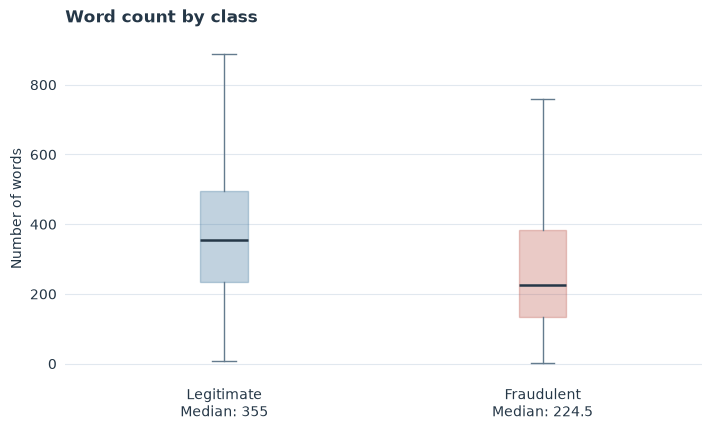

In [30]:
fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
text_jobs.boxplot(
    column="word_count", by="fraudulent", ax=ax, grid=False, showfliers=False,
    patch_artist=True, medianprops={"color": TEXT_COLOR, "linewidth": 1.8},
    whiskerprops={"color": "#647B8E"}, capprops={"color": "#647B8E"},
)

medians = text_jobs.groupby("fraudulent")["word_count"].median().sort_index()
labels = [f"{CLASS_LABELS[label]}\nMedian: {median:g}" for label, median in medians.items()]
ax.set_xticks(range(1, len(labels) + 1), labels=labels)
for label, box in zip(medians.index, ax.patches):
    box.set_facecolor(CLASS_COLORS[label])
    box.set_edgecolor(CLASS_COLORS[label])
    box.set_alpha(0.3)

fig.suptitle("")
ax.set_title("")
ax.set(xlabel="", ylabel="Number of words")
style_axes(ax, "Word count by class")
plt.show()

Fraudulent postings have a lower median word count. The distributions overlap substantially, so word count alone gives limited information about whether a posting is fraudulent. The plot hides points beyond the whiskers so the main distributions are easier to read.

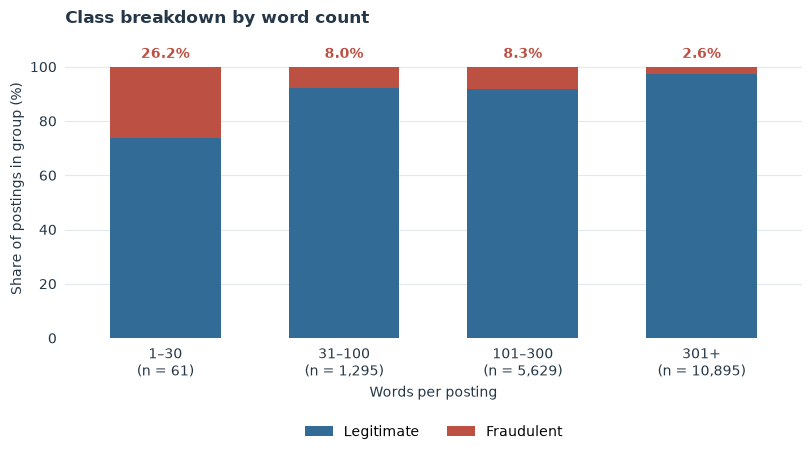

,Legitimate,Fraudulent
Word count range,,
1–30,45,16
31–100,1192,103
101–300,5164,465
301+,10613,282


In [31]:
def plot_text_length(jobs):
    groups = pd.cut(
        jobs["word_count"],
        bins=[0, 30, 100, 300, float("inf")],
        labels=["1–30", "31–100", "101–300", "301+"],
    )

    fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
    counts = fraud_bars(
        jobs.assign(text_length_group=groups),
        "text_length_group",
        ax,
        "Class breakdown by word count",
    )
    ax.set_xlabel("Words per posting")
    return counts


length_counts = plot_text_length(text_jobs)
plt.show()
length_counts.rename(columns={"Real": "Legitimate", "Fake": "Fraudulent"}).rename_axis("Word count range")

Of the **61** postings with 1 to 30 words, **16** are fraudulent (**26.2%**). The fraud rate is **2.6%** among postings with at least 301 words. The shortest group is small, and we keep these postings because they include fraudulent examples.

### Duplicate postings and conflicting labels

We compare all original features after cleaning the text fields. We exclude `job_id` and the target `fraudulent` from the duplicate key. If identical feature rows have conflicting labels, we remove those rows because we cannot tell which label is correct. If the labels agree, we keep the first row.

The same text can appear in distinct postings, for example in listings for different locations. We keep those rows and check that repeated text stays on one side of each split.

The last two rows count extra copies of the combined `text` before and after full duplicate removal. If three postings have identical text, we count the second and third postings, giving two extra copies.

In [32]:
duplicate_columns = jobs.columns.drop(["job_id", "fraudulent"]).tolist()
label_counts = text_jobs.groupby(duplicate_columns, dropna=False)["fraudulent"].transform("nunique")
conflicting_labels = label_counts.gt(1)
consistent_jobs = text_jobs.loc[~conflicting_labels]
deduplicated_jobs = consistent_jobs.drop_duplicates(subset=duplicate_columns).copy()

preparation_summary = pd.Series({
    "Original postings": len(jobs),
    "Empty texts removed": len(jobs) - len(text_jobs),
    "Rows with conflicting labels removed": int(conflicting_labels.sum()),
    "Full duplicate rows removed": len(consistent_jobs) - len(deduplicated_jobs),
    "Postings ready to split": len(deduplicated_jobs),
    "Extra copies of identical text (before)": int(text_jobs["text"].duplicated().sum()),
    "Extra copies of identical text (after)": int(deduplicated_jobs["text"].duplicated().sum()),
}, name="Postings").to_frame()
preparation_summary

,Postings
Original postings,17880
Empty texts removed,0
Rows with conflicting labels removed,0
Full duplicate rows removed,325
Postings ready to split,17555
Extra copies of identical text (before),2001
Extra copies of identical text (after),1676


### Grouped train/test split and cross-validation

We group postings by their cleaned description, ignoring case. If the description is empty, we use the combined text instead. Keeping a group together prevents closely related postings, such as listings with the same description for different cities, from crossing a split.

We use one of five stratified group folds to hold out about **20%** of the postings as the test set and train on the remaining **80%**. Within training, we create five more stratified group folds for model comparison and tuning. Stratification keeps the fraud rate similar across folds while the group constraint keeps related postings together. Every model uses the same folds. We reserve the test set for final evaluation.

In [33]:
from sklearn.model_selection import StratifiedGroupKFold

RANDOM_STATE = 42
N_SPLITS = 5

grouped_jobs = deduplicated_jobs.reset_index(drop=True)
description_key = grouped_jobs["description"].fillna("").str.strip().str.lower()
text_key = grouped_jobs["text"].str.strip().str.lower()
group_key = description_key.mask(description_key.eq(""), text_key)
grouped_jobs["group_id"] = pd.factorize(group_key)[0]

splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
train_indices, test_indices = next(splitter.split(
    grouped_jobs, grouped_jobs["fraudulent"], groups=grouped_jobs["group_id"]
))
train_df = grouped_jobs.iloc[train_indices].reset_index(drop=True)
test_df = grouped_jobs.iloc[test_indices].reset_index(drop=True)

cv_splits = list(splitter.split(train_df, train_df["fraudulent"], groups=train_df["group_id"]))

split_summary = pd.DataFrame([
    {
        "Split": name,
        "Postings": len(frame),
        "Share of data (%)": 100 * len(frame) / len(grouped_jobs),
        "Fraud rate (%)": 100 * frame["fraudulent"].mean(),
    }
    for name, frame in [("Train", train_df), ("Test", test_df)]
]).set_index("Split").round(2)
split_summary

,Postings,Share of data (%),Fraud rate (%)
Split,,,
Train,14044,80.0,4.88
Test,3511,20.0,4.87


### Checks for overlap

We compare train with test and compare the training and validation rows of each CV fold. Every overlap count should be zero. The validation rows come only from the training set. The `job_id` and `group_id` columns are used for matching and splitting. The `fraudulent` column is the target.

In [34]:
def check_split(name, fit_rows, evaluation_rows):
    return {
        "Comparison": name,
        "Evaluation postings": len(evaluation_rows),
        "Fraud rate (%)": 100 * evaluation_rows["fraudulent"].mean(),
        "Shared posting IDs": len(set(fit_rows["job_id"]) & set(evaluation_rows["job_id"])),
        "Shared groups": len(set(fit_rows["group_id"]) & set(evaluation_rows["group_id"])),
        "Shared texts": len(set(fit_rows["text"]) & set(evaluation_rows["text"])),
    }


split_checks = [check_split("Train vs. test", train_df, test_df)]
for fold, (fit_indices, validation_indices) in enumerate(cv_splits, start=1):
    split_checks.append(check_split(
        f"CV fold {fold}", train_df.iloc[fit_indices], train_df.iloc[validation_indices]
    ))

split_checks = pd.DataFrame(split_checks).set_index("Comparison").round(2)
overlap_columns = ["Shared posting IDs", "Shared groups", "Shared texts"]
assert split_checks[overlap_columns].eq(0).all().all(), "Posting overlap found across splits"
split_checks

,Evaluation postings,Fraud rate (%),Shared posting IDs,Shared groups,Shared texts
Comparison,,,,,
Train vs. test,3511,4.87,0,0,0
CV fold 1,2809,4.88,0,0,0
CV fold 2,2809,4.88,0,0,0
CV fold 3,2809,4.88,0,0,0
CV fold 4,2809,4.88,0,0,0
CV fold 5,2808,4.88,0,0,0


## 3. Text classification

| Input | Logistic Regression | Random Forest |
|---|---|---|
| TF-IDF | Word features + LR | Word features + RF |
| School embeddings | Dense vectors + LR | Dense vectors + RF |

### Model selection on the training set

All four models share the five outer validation folds from Section 2. Within each outer fold, a three-fold stratified group search selects hyperparameters by **F1 for fraudulent postings**. F1 gives equal weight to fraud precision and recall. The search refits the selected pipeline on the fitting rows of the outer fold.

We report F1 at the classifier's default decision threshold and **Average Precision (AP)** on the outer validation rows. We save their fraud probabilities for later threshold selection on the training set. A final search refits the selected pipeline on all training rows. The held-out test set is reserved for final evaluation.

The compact grids use settings from the project scripts and keep the five-by-three nested search manageable. Each classifier uses the same settings with both text representations, so we can compare the inputs under the same tuning procedure.

In [35]:
from time import perf_counter

import numpy as np
from sklearn.metrics import average_precision_score, f1_score, make_scorer
from sklearn.model_selection import GridSearchCV

INNER_CV_FOLDS = 3
INNER_CV_SEED = 1
F1_SCORER = make_scorer(f1_score, zero_division=0)


def fit_on_train(estimator, X, y, groups, param_grid):
    inner_splitter = StratifiedGroupKFold(n_splits=INNER_CV_FOLDS, shuffle=True, random_state=INNER_CV_SEED)
    inner_splits = list(inner_splitter.split(X, y, groups))
    search = GridSearchCV(
        estimator, param_grid, scoring=F1_SCORER,
        cv=inner_splits, refit=True, n_jobs=1, error_score="raise",
    )
    search.fit(X, y)
    return search.best_estimator_, search.best_params_


def train_with_cv(estimator, X, y, groups, outer_splits, param_grid):
    started = perf_counter()
    fold_f1 = []
    fold_ap = []
    oof_scores = np.full(len(y), np.nan)

    for fit, validation in outer_splits:
        validation_model, _ = fit_on_train(
            estimator, X[fit], y[fit], groups[fit], param_grid
        )
        X_validation = X[validation]
        positive_column = list(validation_model.classes_).index(1)
        scores = validation_model.predict_proba(X_validation)[:, positive_column]
        oof_scores[validation] = scores
        fold_f1.append(F1_SCORER(validation_model, X_validation, y[validation]))
        fold_ap.append(average_precision_score(y[validation], scores))

    assert np.isfinite(oof_scores).all(), "Missing out-of-fold scores"
    final_model, best_params = fit_on_train(estimator, X, y, groups, param_grid)
    return {
        "model": final_model,
        "best_params": best_params,
        "fold_f1": fold_f1,
        "fold_ap": fold_ap,
        "oof_scores": oof_scores,
        "seconds": perf_counter() - started,
    }

In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

LR_PARAM_GRID = {"classifier__C": [1, 10]}
RF_PARAM_GRID = {"classifier__max_depth": [10, 30]}

y_train = train_df["fraudulent"].to_numpy()
train_groups = train_df["group_id"].to_numpy()
model_results = {}


def logistic_regression():
    return LogisticRegression(
        solver="liblinear", max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    )


def random_forest():
    return RandomForestClassifier(
        n_estimators=100, min_samples_leaf=3, class_weight="balanced_subsample",
        n_jobs=2, random_state=RANDOM_STATE,
    )

### 3.1 TF-IDF + Logistic Regression

We follow the TF-IDF and Logistic Regression pipeline in tfidf_logistic_regression_and_dummy.py. The vectorizer uses single words, up to 20,000 terms and a minimum document frequency of 2. It learns the vocabulary and word weights inside each fitting fold. A temporary cache reuses that transformation for candidates on the same fitting rows.

The classifier uses balanced class weights and searches over C = 1 and 10. C controls the strength of regularization.

In [37]:
from tempfile import TemporaryDirectory

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

TFIDF_MAX_FEATURES = 20_000
TFIDF_MIN_DOC_FREQ = 2

X_train_text = train_df["text"].to_numpy()

with TemporaryDirectory(prefix="tfidf-lr-") as vectorizer_cache:
    tfidf_lr = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, min_df=TFIDF_MIN_DOC_FREQ)),
        ("classifier", logistic_regression()),
    ], memory=vectorizer_cache)
    tfidf_lr_result = train_with_cv(tfidf_lr, X_train_text, y_train, train_groups, cv_splits, LR_PARAM_GRID)
    tfidf_lr_result["model"].memory = None

model_results["TF-IDF + Logistic Regression"] = tfidf_lr_result

### 3.2 TF-IDF + Random Forest

We pair the same TF-IDF transformation with the Random Forest pipeline from tfidf_random_forest.py. We fix 100 trees, three postings per leaf as a minimum, and balanced subsample weights. The compact search compares maximum depths of 10 and 30.

In [38]:
with TemporaryDirectory(prefix="tfidf-rf-") as vectorizer_cache:
    tfidf_rf = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, min_df=TFIDF_MIN_DOC_FREQ)),
        ("classifier", random_forest()),
    ], memory=vectorizer_cache)
    tfidf_rf_result = train_with_cv(tfidf_rf, X_train_text, y_train, train_groups, cv_splits, RF_PARAM_GRID)
    tfidf_rf_result["model"].memory = None

model_results["TF-IDF + Random Forest"] = tfidf_rf_result

### Generate and cache school embeddings

The school endpoint turns each cleaned posting into one embedding vector. If the cache is complete, the notebook validates and loads the saved vectors offline without an API key.

If the cache is missing or incomplete, set `LLM_API_KEY`, `LLM_BASE_URL` and `LLM_EMBED_MODEL` in a local `.env` file. The notebook reads these settings from the file and automatically requests the missing batches. It saves the completed cache in `data/school_embeddings/`. Without a key in `.env`, the TF-IDF models can still run while embedding results remain pending.

Include `embeddings.csv`, `metadata.csv` and `manifest.json` under `data/school_embeddings/` for the offline submission. The manifest records the model, API attempts and generation time for completed batches.

In [39]:
import hashlib
import json
from importlib import import_module
from time import perf_counter

import numpy as np

ENV_FILE = Path(".env")
EMBEDDING_CACHE = Path("data/school_embeddings")
EMBEDDINGS_CSV = "embeddings.csv"
EMBEDDING_METADATA_CSV = "metadata.csv"
EMBEDDING_MANIFEST = "manifest.json"

LITELLM_MODEL_PREFIX = "openai/"
EMBEDDING_BATCH_SIZE = 64
EMBEDDING_TIMEOUT_SECONDS = 60.0
EMBEDDING_RETRIES = 0


def load_embedding_settings():
    if not ENV_FILE.is_file():
        return None

    env = import_module("dotenv").dotenv_values(ENV_FILE, interpolate=False)
    api_key = (env.get("LLM_API_KEY") or env.get("API_KEY") or "").strip()
    if not api_key:
        return None
    base_url = (env.get("LLM_BASE_URL") or env.get("BASE_URL") or "").strip()
    model = (env.get("LLM_EMBED_MODEL") or "").strip()
    if not base_url or not model:
        raise ValueError("Set LLM_BASE_URL and LLM_EMBED_MODEL in .env.")
    return base_url, api_key, model


def write_json(path, value):
    temporary = path.with_suffix(".json.tmp")
    temporary.write_text(json.dumps(value), encoding="utf-8")
    temporary.replace(path)


def validate_vectors(values, n_rows):
    vectors = np.asarray(values, dtype=np.float32)
    if (vectors.ndim != 2 or vectors.shape[0] != n_rows
            or vectors.shape[1] == 0 or not np.isfinite(vectors).all()):
        raise ValueError("Expected one valid embedding vector per posting.")
    return vectors


def get_embeddings(texts, folder, settings, batch_size=EMBEDDING_BATCH_SIZE):
    base_url, api_key, model_name = settings
    model = LITELLM_MODEL_PREFIX + model_name.removeprefix(LITELLM_MODEL_PREFIX)
    folder.mkdir(parents=True, exist_ok=True)
    batches, batch_costs, new_requests = [], {}, 0

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        request = {"base_url": base_url, "model": model_name, "texts": batch}
        key = hashlib.sha256(json.dumps(request, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
        batch_file = folder / f"{key}.json"

        if batch_file.is_file():
            record = json.loads(batch_file.read_text(encoding="utf-8"))
            if record["request_key"] != key:
                raise ValueError("Cached batch does not match the request.")
            vectors = validate_vectors(record["vectors"], len(batch))
        else:
            embedding = import_module("litellm").embedding

            started = perf_counter()
            response = embedding(
                model=model, input=batch, api_base=base_url, api_key=api_key,
                encoding_format="float", timeout=EMBEDDING_TIMEOUT_SECONDS,
                max_retries=EMBEDDING_RETRIES, num_retries=EMBEDDING_RETRIES,
            )
            elapsed = perf_counter() - started
            items = sorted(response.data, key=lambda item: item["index"])
            if [item["index"] for item in items] != list(range(len(batch))):
                raise ValueError("Embedding response indices do not match the batch.")
            vectors = validate_vectors([item["embedding"] for item in items], len(batch))
            record = dict(request_key=key, vectors=vectors.tolist(),
                          endpoint_requests=1, embedding_seconds=elapsed)
            write_json(batch_file, record)
            new_requests += 1

        batches.append(vectors)
        batch_costs[key] = (record["endpoint_requests"], record["embedding_seconds"])

    stats = {
        "embedding_model": model_name,
        "base_url": base_url,
        "batch_size": batch_size,
        "endpoint_requests": sum(count for count, _ in batch_costs.values()),
        "embedding_seconds": sum(seconds for _, seconds in batch_costs.values()),
        "new_endpoint_requests": new_requests,
    }
    return np.concatenate(batches), stats


def metadata_hash(metadata):
    columns = ["job_id", "fraudulent", "text_hash", "group_id", "split", "cv_fold"]
    return hashlib.sha256(metadata[columns].to_csv(index=False).encode()).hexdigest()


def save_embedding_dataset(vectors, metadata, stats, folder):
    table = metadata[["job_id", "text_hash"]].assign(
        embedding=[json.dumps(row.tolist(), separators=(",", ":")) for row in vectors]
    )
    for name, data in [(EMBEDDING_METADATA_CSV, metadata), (EMBEDDINGS_CSV, table)]:
        temporary = folder / f"{name}.tmp"
        data.to_csv(temporary, index=False)
        temporary.replace(folder / name)

    manifest = dict(
        stats, source=f"school/{stats['embedding_model']}", is_mock=False,
        n_rows=len(metadata), dimensions=vectors.shape[1],
        n_folds=metadata.loc[metadata["split"].eq("train"), "cv_fold"].nunique(),
        metadata_sha256=metadata_hash(metadata),
    )
    write_json(folder / EMBEDDING_MANIFEST, manifest)
    return manifest

In [41]:
def build_embedding_metadata(train_df, test_df, cv_splits):
    columns = ["job_id", "fraudulent", "group_id", "text"]
    expected = pd.concat([
        train_df[columns].assign(split="train"),
        test_df[columns].assign(split="test"),
    ], ignore_index=True)
    expected["cv_fold"] = -1
    for fold, (_, validation) in enumerate(cv_splits):
        expected.loc[validation, "cv_fold"] = fold
    expected["text_hash"] = expected["text"].map(lambda text: hashlib.sha256(text.encode()).hexdigest())
    return expected[["job_id", "fraudulent", "text", "text_hash", "group_id", "split", "cv_fold"]]


def get_or_create_school_vectors(folder, metadata):
    required = (EMBEDDINGS_CSV, EMBEDDING_METADATA_CSV, EMBEDDING_MANIFEST)
    if all((folder / name).is_file() for name in required):
        manifest = json.loads((folder / EMBEDDING_MANIFEST).read_text(encoding="utf-8"))
        if manifest["is_mock"] or manifest["metadata_sha256"] != metadata_hash(metadata):
            raise ValueError("The embeddings cache does not match the current dataset and split.")
        table = pd.read_csv(folder / EMBEDDINGS_CSV, keep_default_na=False).set_index("job_id")
        if not table.index.is_unique or set(table.index) != set(metadata["job_id"]):
            raise ValueError("Expected exactly one embedding per posting ID.")
        table = table.loc[metadata["job_id"]]
        if table["text_hash"].tolist() != metadata["text_hash"].tolist():
            raise ValueError("Embedding text hashes do not match the cleaned postings.")
        vectors = validate_vectors(table["embedding"].map(json.loads).tolist(), len(metadata))
        if vectors.shape[1] != manifest["dimensions"]:
            raise ValueError("Unexpected embedding dimensions.")
        return vectors, manifest

    settings = load_embedding_settings()
    if settings is None:
        return None, None

    vectors, stats = get_embeddings(metadata["text"].tolist(), folder / "requests", settings)
    manifest = save_embedding_dataset(vectors, metadata, stats, folder)
    print(f"New API attempts: {stats['new_endpoint_requests']}")
    return vectors, manifest


embedding_metadata = build_embedding_metadata(train_df, test_df, cv_splits)
embedding_vectors, embedding_manifest = get_or_create_school_vectors(EMBEDDING_CACHE, embedding_metadata)
X_train_embeddings = None if embedding_vectors is None else embedding_vectors[:len(train_df)]
if embedding_manifest is None:
    print("School embeddings cache pending. Set LLM_API_KEY in .env to generate it. The TF-IDF comparison can run now.")
else:
    display(pd.Series({
        "Model": embedding_manifest["embedding_model"],
        "Vector dimensions": embedding_vectors.shape[1],
        "API requests": embedding_manifest["endpoint_requests"],
        "Generation time (s)": embedding_manifest["embedding_seconds"],
    }, name="School embeddings").to_frame())

ValueError: Set LLM_BASE_URL and LLM_EMBED_MODEL in .env.

### 3.3 School embeddings + Logistic Regression

The Logistic Regression experiment follows embeddings_logistic_regression.py. It uses the cached school vectors for the training rows and the same C values and class weights as Section 3.1. The scaler is fitted inside the pipeline on each fitting fold.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

if X_train_embeddings is not None:
    embeddings_lr = Pipeline([
        ("scale", StandardScaler()),
        ("classifier", logistic_regression()),
    ])
    model_results["Embeddings + Logistic Regression"] = train_with_cv(
        embeddings_lr, X_train_embeddings, y_train, train_groups, cv_splits, LR_PARAM_GRID
    )
else:
    model_results.pop("Embeddings + Logistic Regression", None)

### 3.4 School embeddings + Random Forest

This experiment uses the cached vectors and the nested training procedure from train_random_forest.py and model_comparison.py. We use the same compact search as Section 3.2 and select hyperparameters by fraud-class F1. The trees learn splits directly on the embedding values.

In [ ]:
# We do not scale the embeddings when applying Random Forest, because it is not sensitive to feature scaling (scaling won't change the result)
if X_train_embeddings is not None:
    embeddings_rf = Pipeline([("classifier", random_forest())])
    model_results["Embeddings + Random Forest"] = train_with_cv(
        embeddings_rf, X_train_embeddings, y_train, train_groups, cv_splits, RF_PARAM_GRID
    )
else:
    model_results.pop("Embeddings + Random Forest", None)

### 3.5 Compare the four models

The 2 x 2 table shows mean F1 across the outer validation folds at the default decision threshold. The detailed table also shows AP, the selected parameters and training time.

In [21]:
model_summary = pd.DataFrame.from_dict({
    name: {
        "Mean outer F1": np.mean(result["fold_f1"]),
        "Outer F1 standard deviation": np.std(result["fold_f1"]),
        "Mean outer AP": np.mean(result["fold_ap"]),
        "CV and refit time (s)": result["seconds"],
        "Selected parameters": ", ".join(
            f"{key.split('__')[-1]}={value}" for key, value in result["best_params"].items()
        ),
    }
    for name, result in model_results.items()
}, orient="index").rename_axis("Model")

classifiers = ("Logistic Regression", "Random Forest")
representations = ("TF-IDF", "Embeddings")
f1_matrix = pd.DataFrame(
    [
        [
            f"{model_summary.loc[name, 'Mean outer F1']:.4f}"
            if name in model_summary.index else "Pending cache"
            for name in (f"{representation} + {classifier}" for classifier in classifiers)
        ]
        for representation in representations
    ],
    index=pd.Index(representations, name="Representation"),
    columns=classifiers,
)
display(f1_matrix)
model_summary.round(4)

,Logistic Regression,Random Forest
Representation,,
TF-IDF,0.7555,0.4827
Embeddings,Pending cache,Pending cache


,Mean outer F1,Outer F1 standard deviation,Mean outer AP,CV and refit time (s),Selected parameters
Model,,,,,
TF-IDF + Logistic Regression,0.7555,0.0393,0.8194,156.2027,C=10
TF-IDF + Random Forest,0.4827,0.0403,0.5604,174.3994,max_depth=10


Read across the matrix to compare classifiers on the same text representation. Read down a column to compare TF-IDF and embeddings with the same classifier.

# 5. Possible future development

- **This project could be enhanced in various ways:**

1. When comparing TF-IDF and Embeddings, only the 5 text columns were used. This is a great starting point, but it would be interesting to see, if appending embeddings directly other variables from the dataset leads to a better result.

2. Using different concatenating techniques of the text columns instead of plain-space joining: adding short labels `Title: ... | Company: Missing | Description: ...` during concatenation could give the embedding model a clearer context.

# 6. Who did what and the use of AI

We worked as a team during the creation of the project and collaborated on it via our GitHub repository: https://github.com/noamorii/4IZ582-fraudulent-job-detection

1. **Nastya**
- Analyzed class balance, plotted real vs. fraudulent postings
- Handled missing values across text columns
- Built DummyClassifier
- Built TF-IDF scores, tuned TF-IDF → Logistic Regression

2. **Julia**
- Analyzed missing values across columns
- Handled duplicates and conflicting labels, created the test holdout and shared CV splits
- Generated and saved text embeddings via the school endpoint
- Built and tuned Embeddings → Logistic Regression.

3. **Olesia**
- Investigated duplicates and metadata features (company logo, employment type, remote work) and plotted their relationship with fraud.
- Cleaned HTML tags and extra spaces, dropped empty postings
- Built cache for the Jupyter Notebook 
- Built and tuned Embeddings → Random Forest

